<a href="https://colab.research.google.com/github/haseenbabu578-web/cat-and-dog-clasification-deep-learning/blob/main/Dog_Cat_Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

print("Dog vs Cat Deep Learning Project")
print("Environment setup successful!")


TensorFlow version: 2.21.0
GPU available: True
Dog vs Cat Deep Learning Project
Environment setup successful!


In [ ]:

import os
import urllib.request
import zipfile

url = (
    "https://download.microsoft.com/download/"
    "3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/"
    "kagglecatsanddogs_5340.zip"
)

zip_path = "/content/cats_dogs.zip"
extract_dir = "/content/cats_dogs_data"

print("Downloading dataset... This may take a few minutes.")

urllib.request.urlretrieve(url, zip_path)

print("Download complete!")
print("File size:", round(os.path.getsize(zip_path) / 1e6, 2), "MB")

os.makedirs(extract_dir, exist_ok=True)

print("Extracting images...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extraction complete!")

for root, dirs, files in os.walk(extract_dir):
    if files:
        print(root, "->", len(files), "files")


Download complete!
File size: 824.89 MB
Extracting images...
Extraction complete!
/content/cats_dogs_data -> 2 files
/content/cats_dogs_data/PetImages/Dog -> 12501 files
/content/cats_dogs_data/PetImages/Cat -> 12501 files


In [ ]:

import os
from PIL import Image, UnidentifiedImageError

DATA_DIR = "/content/cats_dogs_data/PetImages"

valid_images = {"Cat": [], "Dog": []}
corrupt_images = []

for label in ["Cat", "Dog"]:
    folder = os.path.join(DATA_DIR, label)

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        try:
            with Image.open(filepath) as img:
                img.verify()

            # Verify the image can also be fully decoded.
            with Image.open(filepath) as img:
                img.convert("RGB").load()

            valid_images[label].append(filepath)

        except (OSError, ValueError, UnidentifiedImageError):
            corrupt_images.append(filepath)

print("Dataset integrity check completed!")
print("Valid Cat images:", len(valid_images["Cat"]))
print("Valid Dog images:", len(valid_images["Dog"]))
print("Corrupt images:", len(corrupt_images))



/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Dataset integrity check completed!
Valid Cat images: 12499
Valid Dog images: 12499
Corrupt images: 4


In [ ]:

import random
import shutil
from pathlib import Path

random.seed(42)

OUTPUT_DIR = Path("/content/dog_cat_dataset")

for split in ["train", "val", "test"]:
    for label in ["Cat", "Dog"]:
        (OUTPUT_DIR / split / label).mkdir(
            parents=True,
            exist_ok=True
        )

for label, paths in valid_images.items():
    paths = paths.copy()
    random.shuffle(paths)

    n = len(paths)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    split_data = {
        "train": paths[:train_end],
        "val": paths[train_end:val_end],
        "test": paths[val_end:]
    }

    for split, files in split_data.items():
        for src in files:
            destination = (
                OUTPUT_DIR / split / label / Path(src).name
            )
            shutil.copy2(src, destination)

print("Dataset split completed!")

for split in ["train", "val", "test"]:
    for label in ["Cat", "Dog"]:
        count = len(list((OUTPUT_DIR / split / label).iterdir()))
        print(f"{split}/{label}: {count}")


Dataset split completed!
train/Cat: 8749
train/Dog: 8749
val/Cat: 1875
val/Dog: 1875
test/Cat: 1875
test/Dog: 1875


In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("/content/dog_cat_dataset")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for label in ["Cat", "Dog"]:
        folder = OUTPUT_DIR / split / label
        count = len(list(folder.iterdir()))
        print(f"{label}: {count}")


TRAIN
Cat: 8749
Dog: 8749

VAL
Cat: 1875
Dog: 1875

TEST
Cat: 1875
Dog: 1875


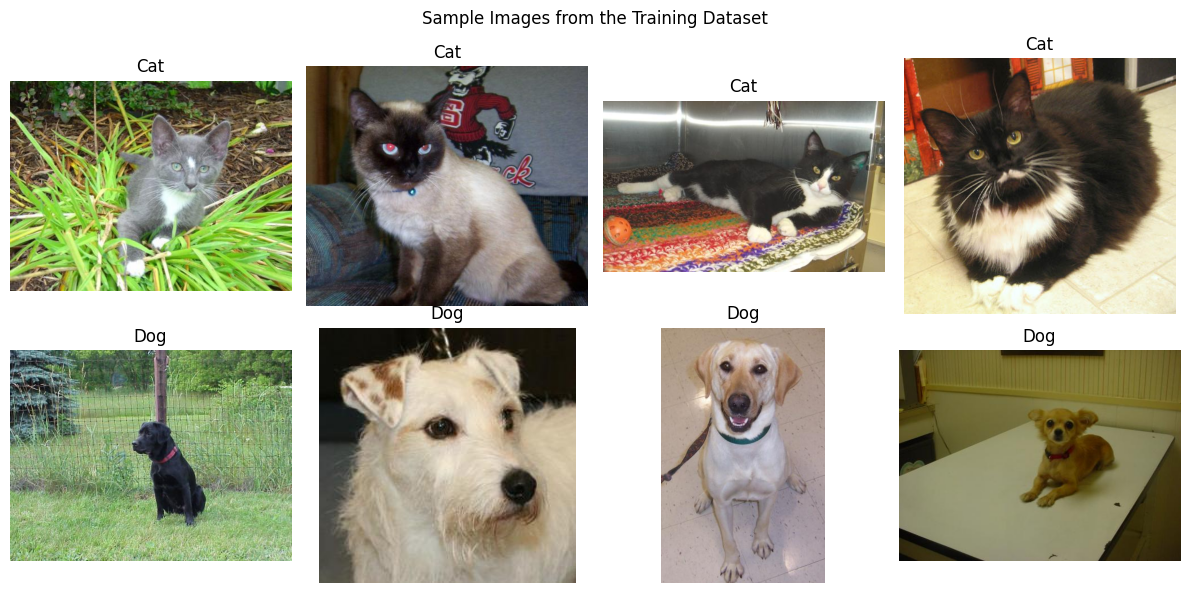

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

DATA_DIR = Path("/content/dog_cat_dataset/train")
random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, label in enumerate(["Cat", "Dog"]):
    paths = list((DATA_DIR / label).glob("*"))
    samples = random.sample(paths, 4)

    for col, path in enumerate(samples):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.suptitle("Sample Images from the Training Dataset")
plt.tight_layout()
plt.show()


In [ ]:

print("Class names:", ["Cat", "Dog"])
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

print("TensorFlow pipeline ready!")



Class names: ['Cat', 'Dog']
Image size: (224, 224)
Batch size: 32
TensorFlow pipeline ready!


In [ ]:

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print(
        "Pixel value range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

    print(
        "First 10 labels:",
        labels.numpy().reshape(-1)[:10].astype(int)
    )


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 1)
Pixel value range: 0.0 to 255.0
First 10 labels: [0 0 0 0 1 1 1 1 0 0]


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models

baseline_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Normalize pixels from 0-255 to 0-1
    layers.Rescaling(1.0 / 255),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # 0 = Cat, 1 = Dog
    layers.Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

from tensorflow.keras import layers, models
import tensorflow as tf

baseline_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    # More parameter-efficient than Flatten()
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

import os
from pathlib import Path
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = False

SOURCE_DIR = Path("/content/dog_cat_dataset")
CLEAN_DIR = Path("/content/dog_cat_clean")

for split in ["train", "val", "test"]:
    for label in ["Cat", "Dog"]:
        src_folder = SOURCE_DIR / split / label
        dst_folder = CLEAN_DIR / split / label
        dst_folder.mkdir(parents=True, exist_ok=True)

        good = 0
        bad = 0

        for path in src_folder.iterdir():
            try:
                with Image.open(path) as img:
                    img.load()
                    rgb = img.convert("RGB")
                    output_path = dst_folder / f"{path.stem}.jpg"
                    rgb.save(output_path, format="JPEG", quality=95)
                good += 1

            except Exception as error:
                bad += 1
                print("Skipped:", path.name, "|", str(error)[:100])

        print(f"{split}/{label}: {good} converted, {bad} skipped")

print("\nRGB conversion completed!")


train/Cat: 8749 converted, 0 skipped
train/Dog: 8749 converted, 0 skipped
val/Cat: 1875 converted, 0 skipped
val/Dog: 1875 converted, 0 skipped
test/Cat: 1875 converted, 0 skipped
test/Dog: 1875 converted, 0 skipped

RGB conversion completed!


In [ ]:

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/dog_cat_clean/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cat", "Dog"],
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/dog_cat_clean/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cat", "Dog"],
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/dog_cat_clean/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cat", "Dog"],
    shuffle=False
)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Clean TensorFlow datasets are ready!")


Found 17498 files belonging to 2 classes.
Found 3750 files belonging to 2 classes.
Found 3750 files belonging to 2 classes.
Clean TensorFlow datasets are ready!


In [ ]:

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)


Epoch 1/3
547/547 ━━━━━━━━━━━━━━━━━━━━ 45s 76ms/step - accuracy: 0.5908 - loss: 0.6608 - val_accuracy: 0.5581 - val_loss: 0.6786
Epoch 2/3
547/547 ━━━━━━━━━━━━━━━━━━━━ 34s 62ms/step - accuracy: 0.6448 - loss: 0.6270 - val_accuracy: 0.7037 - val_loss: 0.5859
Epoch 3/3
547/547 ━━━━━━━━━━━━━━━━━━━━ 34s 61ms/step - accuracy: 0.7012 - loss: 0.5791 - val_accuracy: 0.7005 - val_loss: 0.5769


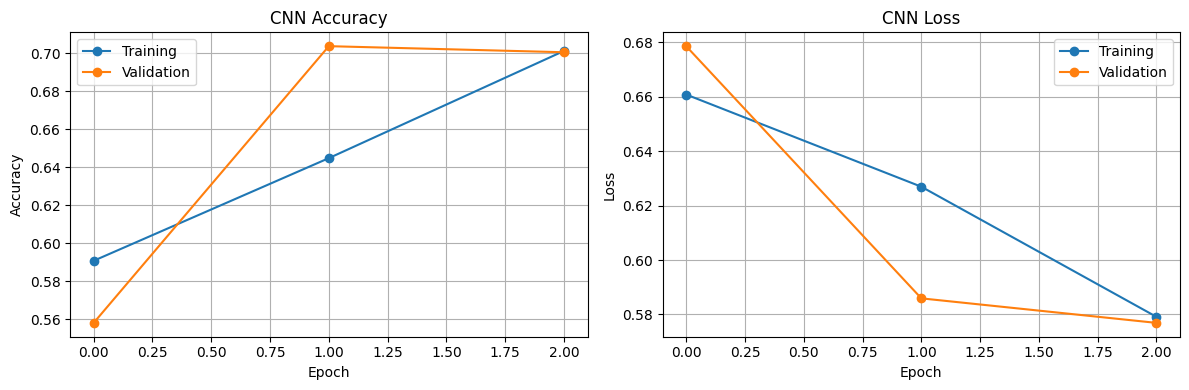

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training")
plt.plot(history.history["val_loss"], marker="o", label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf

from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input
)

AUTOTUNE = tf.data.AUTOTUNE

def prepare_mobilenet(images, labels):
    images = preprocess_input(images)
    return images, labels

train_tl = train_ds.map(
    prepare_mobilenet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_tl = val_ds.map(
    prepare_mobilenet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_tl = test_ds.map(
    prepare_mobilenet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("MobileNetV2 data pipeline ready!")


MobileNetV2 data pipeline ready!


In [ ]:

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers for initial training.
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

tl_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_mobilenet.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

tl_history = model.fit(
    train_tl,
    validation_data=val_tl,
    epochs=3,
    callbacks=tl_callbacks
)


Epoch 1/3
547/547 ━━━━━━━━━━━━━━━━━━━━ 53s 75ms/step - accuracy: 0.9717 - loss: 0.0821 - val_accuracy: 0.9867 - val_loss: 0.0364
Epoch 2/3
547/547 ━━━━━━━━━━━━━━━━━━━━ 35s 63ms/step - accuracy: 0.9869 - loss: 0.0390 - val_accuracy: 0.9880 - val_loss: 0.0362
Epoch 3/3
547/547 ━━━━━━━━━━━━━━━━━━━━ 34s 62ms/step - accuracy: 0.9886 - loss: 0.0348 - val_accuracy: 0.9869 - val_loss: 0.0336


In [ ]:

import tensorflow as tf

best_model = tf.keras.models.load_model(
    "/content/best_mobilenet.keras"
)

test_loss, test_accuracy = best_model.evaluate(test_tl)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - accuracy: 0.9896 - loss: 0.0319
Test Loss: 0.0319
Test Accuracy: 98.96%


In [ ]:

import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_tl
]).astype(int)

y_scores = best_model.predict(test_tl, verbose=1).reshape(-1)
y_pred = (y_scores >= 0.5).astype(int)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Cat", "Dog"],
    digits=4
))


118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 70ms/step
              precision    recall  f1-score   support

         Cat     0.9941    0.9851    0.9896      1875
         Dog     0.9852    0.9941    0.9896      1875

    accuracy                         0.9896      3750
   macro avg     0.9896    0.9896    0.9896      3750
weighted avg     0.9896    0.9896    0.9896      3750



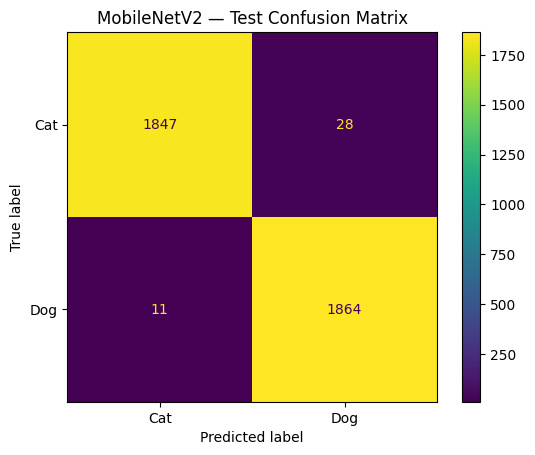

In [ ]:

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot()
plt.title("MobileNetV2 — Test Confusion Matrix")
plt.show()


In [ ]:

best_model.save("/content/dog_cat_model.keras")

print("Final model saved successfully!")


Final model saved successfully!


In [ ]:

test_loss, test_accuracy = best_model.evaluate(test_tl)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


118/118 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.9896 - loss: 0.0319
Test loss: 0.0319
Test accuracy: 98.96%


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("RGB")
    resized = image.resize((224, 224))

    array = np.array(resized, dtype=np.float32)
    array = np.expand_dims(array, axis=0)
    array = preprocess_input(array)

    dog_score = float(
        best_model.predict(array, verbose=0)[0][0]
    )

    prediction = "Dog" if dog_score >= 0.5 else "Cat"
    confidence = dog_score if prediction == "Dog" else 1 - dog_score

    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{prediction} | Model score: {confidence * 100:.2f}%"
    )
    plt.show()

    print("Predicted class:", prediction)
    print(f"Model score for predicted class: {confidence * 100:.2f}%")
